# Falling Rents — Plotting Data for the Web Page

Writes front-end-ready JSON for `src/routes/falling-rents` into `src/data/falling-rents/`.
All analysis and geometry processing happens here so the Svelte components only have to draw.

Each visualization is a numbered `vis` export, mirroring `rising-rents-supply/create_rental_plotting_data.ipynb`.
The analysis these figures come from lives in `explore_falling_rents.ipynb`.

## VIS 1 — Net change in asking rents since 2019 (map)

One spike / arrow per CMA, sized by the **net percentage change in asking rent** between the first quarter of the
StatCan series (Q1 2019) and the latest quarter. This is deliberately the *net* figure, not the post-peak decline:
the point of the map is that, even after the recent softening, rents are still far above where they were in 2019.

- Series: StatCan Table 46-10-0092-01, 2-bedroom apartment asking rent (same headline series as `explore_falling_rents.ipynb`).
- Cities: every CMA with at least `MIN_QUARTERS` quarters of data and a Q1 2019 observation.
- Geometry: StatCan cartographic provincial boundaries, projected to Lambert conformal conic (EPSG:3347), cropped to the
  populated south, heavily simplified, and shipped as plain GeoJSON in **kilometres** so the front end can use
  `d3.geoIdentity()` with no projection work.
- Frames: one national frame plus three zoomed **insets** — Southern BC, Southern Ontario (with Ottawa) and Southern Quebec —
  where cities are too tightly packed to read at national scale. The two corridor insets are **rotated** (30° clockwise) so the
  Windsor–Québec City corridor runs left-to-right and fits a short, wide box.
- Arrow angle: chosen here by counting arrow overlaps at each candidate tilt, rather than by eye (see "Choosing the arrow tilt").

In [1]:
from itertools import combinations
from pathlib import Path
import json

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyproj import Transformer
from shapely import affinity
from shapely.geometry import MultiPolygon, Polygon, box, mapping
from shapely.geometry.polygon import orient

/home/aniket/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
# ── Paths ─────────────────────────────────────────────────────────────
ASKING_ROOT   = Path('../../data/statscan-quarterly-rental-clean/can-cma-all')
PROVINCE_PATH = Path('../../data/geo/canada_provinces.geojson')   # StatCan provincial cartographic boundaries
OUT_DIR       = Path('../../src/data/falling-rents')
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ── Series definition (matches explore_falling_rents.ipynb) ──────────
BED_COLUMN       = 'Apt 2br'
BED_LABEL        = '2-bedroom apartment'
BASELINE_QUARTER = 'Q1 2019'
MIN_QUARTERS     = 8

# ── Geometry settings ────────────────────────────────────────────────
PROJ_CRS          = 'EPSG:3347'    # StatCan Lambert conformal conic
MAIN_SIMPLIFY_KM  = 4.0            # shoreline simplification, national frame
INSET_SIMPLIFY_KM = 1.5            # finer, because insets are drawn 2.5-4x larger
MIN_ISLAND_KM2    = 3000           # national frame: drop islands smaller than this (keeps PEI, Cape Breton, Vancouver Is., Haida Gwaii, Anticosti)
INSET_MIN_ISLAND_KM2 = 150         # insets are drawn much larger, so keep small islands that matter (Island of Montreal ~690 km2, Salt Spring ~180 km2)

# Arrows are drawn in four size classes (length / thickness / colour per class). These mirror CLASS_BREAKS / CLASS_LEN_FRAC in CanadaGlyphMap.svelte.
CLASS_BREAKS   = [25, 50, 75]               # % change; four classes: <25, 25-50, 50-75, 75+
CLASS_LEN_FRAC = [0.36, 0.58, 0.80, 1.0]    # arrow length as a share of the longest arrow

# National frame: west edge just past Vancouver Island, east edge just past Newfoundland, south edge under Point Pelee.
# The north edge is a hard crop a little above the northernmost cities (in this projection Edmonton / St. John's, ~2,170 km).
# The east pad leaves room for tilted arrows near St. John's.
MAIN_PAD_KM = dict(west=140, east=260, north_above_cities=430)

# ── Insets ────────────────────────────────────────────────────────────
# Each inset zooms on a padded box around its anchor cities.
#   rotation   degrees counter-clockwise applied to the map in that inset (negative = clockwise), to fit a diagonal area to a wide box
#   pad_km     breathing room around the anchor cities, measured in the (rotated) inset frame
#   row        which row it sits in on narrow screens (desktop puts all insets in one row, in `order`)
#   zoom       box width = visible width x zoom x the row's shared scale, so denser areas can be magnified more
INSETS = [
    # Kamloops and Kelowna are far enough inland to read fine at national scale, so this inset zooms on the
    # Vancouver Island / Lower Mainland cluster instead (zoom 1.9x the shared inset scale, since it is the densest).
    dict(id='bc', title='Southern BC', rotation=0, order=0, row=0, zoom=1.9,
         anchors=['victoria', 'nanaimo', 'vancouver', 'abbotsford-mission', 'chilliwack'],
         pad_km=dict(west=95, east=95, south=75, north=60)),
    dict(id='on', title='Southern Ontario & Ottawa', rotation=-30, order=1, row=1, zoom=1.0,
         anchors=['windsor', 'london', 'kitchener-cambridge-waterloo', 'guelph', 'brantford', 'st. catharines-niagara',
                  'hamilton', 'toronto', 'barrie', 'oshawa', 'peterborough', 'belleville-quinte west', 'kingston',
                  'ottawa', 'gatineau'],
         pad_km=dict(west=85, east=85, south=80, north=45)),
    dict(id='qc', title='Southern Quebec', rotation=-30, order=2, row=0, zoom=1.0,
         anchors=['ottawa', 'gatineau', 'montreal', 'sherbrooke', 'drummondville', 'quebec'],
         pad_km=dict(west=95, east=95, south=80, north=45)),
]
GENEROUS_KM = 220   # geometry is clipped this far beyond the visible box so the page can show a taller/wider box without gaps

# ── City centres (lat, lon) and display names ────────────────────────
# Neither the rent files nor data/reference carry coordinates, so city-centre points
# are listed here. Spikes are drawn at these points, not at CMA centroids.
CITY_COORDS = {
    'abbotsford-mission': (49.05, -122.30), 'barrie': (44.39, -79.69),
    'belleville-quinte west': (44.16, -77.38), 'brantford': (43.14, -80.26),
    'calgary': (51.05, -114.07), 'chilliwack': (49.16, -121.95),
    'drummondville': (45.88, -72.48), 'edmonton': (53.55, -113.49),
    'fredericton': (45.96, -66.64), 'gatineau': (45.48, -75.65),
    'greater sudbury': (46.49, -81.00), 'guelph': (43.55, -80.25),
    'halifax': (44.65, -63.58), 'hamilton': (43.26, -79.87),
    'kamloops': (50.67, -120.33), 'kelowna': (49.89, -119.50),
    'kingston': (44.23, -76.48), 'kitchener-cambridge-waterloo': (43.45, -80.49),
    'lethbridge': (49.69, -112.84), 'london': (42.98, -81.25),
    'moncton': (46.09, -64.78), 'montreal': (45.50, -73.57),
    'nanaimo': (49.17, -123.94), 'oshawa': (43.90, -78.85),
    'ottawa': (45.42, -75.70), 'peterborough': (44.30, -78.32),
    'quebec': (46.81, -71.21), 'red deer': (52.27, -113.81),
    'regina': (50.45, -104.61), 'saguenay': (48.43, -71.07),
    'saint john': (45.27, -66.06), 'saskatoon': (52.13, -106.67),
    'sherbrooke': (45.40, -71.89), 'st. catharines-niagara': (43.16, -79.24),
    "st. john's": (47.56, -52.71), 'thunder bay': (48.38, -89.25),
    'toronto': (43.65, -79.38), 'trois-rivieres': (46.34, -72.54),
    'vancouver': (49.28, -123.12), 'victoria': (48.43, -123.37),
    'windsor': (42.32, -83.04), 'winnipeg': (49.90, -97.14),
}

DISPLAY_NAME = {
    'abbotsford-mission': 'Abbotsford–Mission', 'belleville-quinte west': 'Belleville–Quinte West',
    'kitchener-cambridge-waterloo': 'Kitchener–Cambridge–Waterloo', 'montreal': 'Montréal',
    'quebec': 'Québec City', 'saguenay': 'Saguenay', 'st. catharines-niagara': 'St. Catharines–Niagara',
    "st. john's": "St. John's", 'trois-rivieres': 'Trois-Rivières', 'greater sudbury': 'Greater Sudbury',
    'saint john': 'Saint John', 'red deer': 'Red Deer', 'thunder bay': 'Thunder Bay',
}

CMA_PROVINCE = pd.read_csv('../../data/reference/cma_to_province.csv').set_index('cma')['province'].to_dict()

# Label priority (same for every frame): the biggest metropolitan areas first, then any city with a large increase,
# then everything else by size of increase. The page tries labels in this order, puts each beside the city's own dot,
# and silently skips any whose text would collide with an arrow or another label (hover / tap still names every city).
MAJOR_CITIES = ['toronto', 'montreal', 'vancouver', 'calgary', 'edmonton', 'ottawa', 'winnipeg', 'quebec', 'hamilton',
                'kitchener-cambridge-waterloo', 'london', 'halifax', 'st. catharines-niagara', 'oshawa', 'victoria', 'windsor',
                'saskatoon', 'regina', "st. john's", 'sherbrooke', 'barrie', 'kelowna', 'abbotsford-mission', 'kingston']
BIG_INCREASE_PCT = 70   # cities at or above this are named right after the major cities
LABEL_TEXT = {('bc', 'abbotsford-mission'): 'Abbotsford', ('on', 'kitchener-cambridge-waterloo'): 'Kitchener',
              ('on', 'st. catharines-niagara'): 'St. Catharines', ('on', 'belleville-quinte west'): 'Belleville'}

# Ottawa and Gatineau centres are ~4 km apart, which would stack their glyphs into one.
# Nudge them apart (km) so both stay visible; hover/tap still names each correctly.
NUDGE_KM = {'ottawa': (-9, -4), 'gatineau': (9, 4)}

### Net change per city

`net_change_pct = (latest / Q1 2019 − 1) × 100`, using the 2-bedroom asking-rent series. The Canada-wide figure uses StatCan's own
"All CMAs" aggregate (`all.csv`), the same national series used in `explore_falling_rents.ipynb`.

In [3]:
def load_series(fp: Path) -> pd.Series:
    df = pd.read_csv(fp)
    return df.set_index('Quarter')[BED_COLUMN].dropna()


def quarter_key(label: str):
    q, y = label.split()
    return (int(y), int(q[1]))


rows, skipped = [], []
for fp in sorted(ASKING_ROOT.glob('*.csv')):
    if fp.stem == 'all':
        continue
    s = load_series(fp)
    if len(s) < MIN_QUARTERS or BASELINE_QUARTER not in s.index:
        skipped.append(fp.stem)
        continue
    s = s.loc[sorted(s.index, key=quarter_key)]
    base, latest = float(s[BASELINE_QUARTER]), float(s.iloc[-1])
    rows.append({
        'key': fp.stem,
        'latest_quarter': s.index[-1],
        'base_rent': round(base),
        'latest_rent': round(latest),
        'pct_change': round((latest / base - 1) * 100, 1),
    })

net = pd.DataFrame(rows)
assert net['latest_quarter'].nunique() == 1, 'cities disagree on the latest quarter'
LATEST_QUARTER = net['latest_quarter'].iloc[0]

nat = load_series(ASKING_ROOT / 'all.csv')
nat_pct = round((nat.iloc[-1] / nat[BASELINE_QUARTER] - 1) * 100, 1)

print(f'{len(net)} cities with data, {BASELINE_QUARTER} -> {LATEST_QUARTER}')
print(f'skipped (too little {BED_LABEL} data): {skipped}')
print(f'Canada-wide (All CMAs): ${nat[BASELINE_QUARTER]:,.0f} -> ${nat.iloc[-1]:,.0f}  ({nat_pct:+.1f}%)')
pc = net['pct_change']
print(f'median {pc.median():.1f}%  |  range {pc.min():.1f}% to {pc.max():.1f}%')
net.sort_values('pct_change', ascending=False).head(5)

40 cities with data, Q1 2019 -> Q1 2026
skipped (too little 2-bedroom apartment data): ['saguenay', 'trois-rivieres']
Canada-wide (All CMAs): $1,520 -> $2,150  (+41.4%)
median 47.0%  |  range 3.9% to 105.0%


,key,latest_quarter,base_rent,latest_rent,pct_change
6,drummondville,Q1 2026,600,1230,105.0
31,sherbrooke,Q1 2026,660,1250,89.4
12,halifax,Q1 2026,1290,2350,82.2
33,st. john's,Q1 2026,900,1570,74.4
20,moncton,Q1 2026,860,1470,70.9


### Project city points and build the frames

Everything is projected to EPSG:3347 and expressed in **km**, north-up. The front end flips y when it draws (`geoIdentity().reflectY(true)`).
Each inset gets its own coordinates: the same projected points rotated about the inset's centre.

In [4]:
to_proj = Transformer.from_crs('EPSG:4326', PROJ_CRS, always_xy=True)

def project_km(lat, lon):
    x, y = to_proj.transform(lon, lat)
    return x / 1000, y / 1000

def city_xy(key):
    x, y = project_km(*CITY_COORDS[key])
    dx, dy = NUDGE_KM.get(key, (0, 0))
    return np.array([x + dx, y + dy])

net['xy'] = [city_xy(k) for k in net['key']]
net['city'] = [DISPLAY_NAME.get(k, k.title()) for k in net['key']]
net['province'] = net['key'].map(CMA_PROVINCE)
assert net['province'].notna().all()
net = net.sort_values('pct_change', ascending=False).reset_index(drop=True)   # row order == `cities` order in the JSON
key_to_idx = {k: i for i, k in enumerate(net['key'])}
XY = np.vstack(net['xy'])

def rotate_pts(pts, deg, origin):
    t = np.radians(deg)
    R = np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])
    return (np.atleast_2d(pts) - origin) @ R.T + origin

def label_rank(key):
    """Sort key: major cities (by size) first, then big increases, then the rest by increase."""
    pct = float(net.loc[key_to_idx[key], 'pct_change'])
    if key in MAJOR_CITIES:
        return (0, MAJOR_CITIES.index(key))
    return (1, -pct) if pct >= BIG_INCREASE_PCT else (2, -pct)

def label_entries(frame_id, idxs):
    out = []
    for key in sorted(key_to_idx, key=label_rank):
        i = key_to_idx[key]
        if i in idxs:
            entry = {'i': i}
            if key in MAJOR_CITIES:
                entry['major'] = True     # the page may let a major city's label cross a neighbour's arrow rather than drop it
            if (frame_id, key) in LABEL_TEXT:
                entry['text'] = LABEL_TEXT[(frame_id, key)]
            out.append(entry)
    return out

# ── National frame (km) ──────────────────────────────────────────────
main_extent = [XY[:, 0].min() - MAIN_PAD_KM['west'], city_xy('windsor')[1] - 140,
               XY[:, 0].max() + MAIN_PAD_KM['east'], XY[:, 1].max() + MAIN_PAD_KM['north_above_cities']]

# ── Inset frames ─────────────────────────────────────────────────────
for ins in INSETS:
    anchors = np.array([city_xy(k) for k in ins['anchors']])
    ins['origin'] = anchors.mean(axis=0)
    a_rot = rotate_pts(anchors, ins['rotation'], ins['origin'])
    pad = ins['pad_km']
    ins['fit'] = [a_rot[:, 0].min() - pad['west'], a_rot[:, 1].min() - pad['south'],
                  a_rot[:, 0].max() + pad['east'], a_rot[:, 1].max() + pad['north']]
    ins['extent'] = [ins['fit'][0] - GENEROUS_KM, ins['fit'][1] - GENEROUS_KM,
                     ins['fit'][2] + GENEROUS_KM, ins['fit'][3] + GENEROUS_KM]
    pts_rot = rotate_pts(XY, ins['rotation'], ins['origin'])
    f = ins['fit']
    ins['member_idx'] = [i for i, (x, y) in enumerate(pts_rot) if f[0] <= x <= f[2] and f[1] <= y <= f[3]]
    ins['pts_rot'] = pts_rot
    # the visible box, drawn back on the national map as a (rotated) outline
    ins['region'] = rotate_pts(np.array(box(*f).exterior.coords)[:-1], -ins['rotation'], ins['origin'])
    print(f"{ins['id']:3s} rot {ins['rotation']:4d}°  fit {f[2]-f[0]:.0f} x {f[3]-f[1]:.0f} km  "
          f"{len(ins['member_idx'])} cities: {sorted(net.loc[ins['member_idx'], 'city'])}")

in_any_inset = set(i for ins in INSETS for i in ins['member_idx'])
print(f"national frame: {main_extent[2]-main_extent[0]:.0f} x {main_extent[3]-main_extent[1]:.0f} km;  "
      f"{len(in_any_inset)} of {len(net)} cities also appear in an inset")

bc  rot    0°  fit 320 x 227 km  5 cities: ['Abbotsford–Mission', 'Chilliwack', 'Nanaimo', 'Vancouver', 'Victoria']
on  rot  -30°  fit 870 x 290 km  15 cities: ['Barrie', 'Belleville–Quinte West', 'Brantford', 'Gatineau', 'Guelph', 'Hamilton', 'Kingston', 'Kitchener–Cambridge–Waterloo', 'London', 'Oshawa', 'Ottawa', 'Peterborough', 'St. Catharines–Niagara', 'Toronto', 'Windsor']
qc  rot  -30°  fit 578 x 270 km  7 cities: ['Drummondville', 'Gatineau', 'Kingston', 'Montréal', 'Ottawa', 'Québec City', 'Sherbrooke']
national frame: 5423 x 2011 km;  24 of 40 cities also appear in an inset


In [5]:
prov = gpd.read_file(PROVINCE_PATH).to_crs(PROJ_CRS)
prov['geometry'] = prov.geometry.scale(xfact=0.001, yfact=0.001, origin=(0, 0))   # work in km from here on
prov = prov[['PRENAME', 'PREABBR', 'geometry']].rename(columns={'PRENAME': 'name', 'PREABBR': 'abbr'})


def make_frame(clip_poly, tolerance_km, rotation=0, origin=None, min_island_km2=MIN_ISLAND_KM2):
    """Clip provinces to a polygon (given in the *frame's* coordinates), simplify across shared borders, drop small islands.
    For rotated insets the clip polygon is rotated back into map space, intersected there, then the result is rotated forward."""
    simplified = prov.geometry.simplify_coverage(tolerance_km)
    clip = affinity.rotate(clip_poly, -rotation, origin=tuple(origin)) if rotation else clip_poly
    parts = []
    for name, abbr, geom in zip(prov.name, prov.abbr, simplified):
        g = geom.intersection(clip)
        if g.is_empty:
            continue
        polys = [p for p in (g.geoms if hasattr(g, 'geoms') else [g])
                 if p.geom_type == 'Polygon' and p.area >= min_island_km2]
        if not polys:
            continue
        u = gpd.GeoSeries(polys).union_all()
        if rotation:
            u = affinity.rotate(u, rotation, origin=tuple(origin))
        parts.append({'name': name, 'abbr': abbr, 'geometry': u})
    return gpd.GeoDataFrame(parts, crs=PROJ_CRS)


def to_feature_collection(gdf):
    # coordinates rounded to 0.1 km (~100 m): far below what's visible at any display size
    feats = []
    for name, abbr, geom in zip(gdf['name'], gdf['abbr'], gdf.geometry):
        # consistent ring winding (exterior CCW, holes CW) so SVG fills never invert
        polys = list(geom.geoms) if hasattr(geom, 'geoms') else [geom]
        gj = mapping(MultiPolygon([orient(p, 1.0) for p in polys]))
        def rnd(c):
            return [round(c[0], 1), round(c[1], 1)] if isinstance(c[0], (int, float)) else [rnd(i) for i in c]
        gj = {'type': gj['type'], 'coordinates': rnd(gj['coordinates'])}
        feats.append({'type': 'Feature', 'properties': {'name': name, 'abbr': abbr}, 'geometry': gj})
    return {'type': 'FeatureCollection', 'features': feats}


def n_polys(gdf):
    return sum(len(g.geoms) if hasattr(g, 'geoms') else 1 for g in gdf.geometry)

main_prov = make_frame(box(*main_extent), MAIN_SIMPLIFY_KM)
print(f'main: {len(main_prov)} provinces, {n_polys(main_prov)} polygons')
for ins in INSETS:
    ins['prov'] = make_frame(box(*ins['extent']), INSET_SIMPLIFY_KM, ins['rotation'], ins['origin'], INSET_MIN_ISLAND_KM2)
    print(f"{ins['id']}: {len(ins['prov'])} provinces, {n_polys(ins['prov'])} polygons")

main: 10 provinces, 14 polygons


bc: 1 provinces, 9 polygons


on: 2 provinces, 9 polygons
qc: 3 provinces, 9 polygons


### Choosing the arrow tilt

Arrows collide when a city's arrow points at a neighbour — Alberta's cities line up about 27° off vertical, the Windsor–Québec corridor about 49°,
so any single tilt helps one region and hurts another. Rather than pick by eye, count overlapping arrow pairs (segments within `THRESH_PX`)
at every candidate tilt, in every frame, at both a desktop and a phone layout, and take the minimum.

Pixel sizes mirror the page's layout rules (length scale and zoom) closely enough to rank angles; they are not exact.
Cities that sit inside an inset region are drawn faintly on the national map and are excluded from its count.

In [6]:
THRESH_PX = 3.5
MAX_LEN_SPEC = lambda w: min(70, max(38, w * 0.10))      # px length of the longest arrow at map width w (mirrors the page)
vals = net['pct_change'].to_numpy()
class_idx = np.array([sum(v >= b for b in CLASS_BREAKS) for v in vals])
len_frac = np.array(CLASS_LEN_FRAC)[class_idx]               # arrows come in four lengths, not a continuous scale


def seg_dist(a0, a1, b0, b1):
    def pt_seg(p, q0, q1):
        d = q1 - q0
        t = np.clip(np.dot(p - q0, d) / max(np.dot(d, d), 1e-9), 0, 1)
        return np.linalg.norm(p - (q0 + t * d))
    def ccw(a, b, c):
        return (c[1] - a[1]) * (b[0] - a[0]) - (b[1] - a[1]) * (c[0] - a[0])
    if ccw(a0, b0, b1) * ccw(a1, b0, b1) < 0 and ccw(a0, a1, b0) * ccw(a0, a1, b1) < 0:
        return 0.0
    return min(pt_seg(a0, b0, b1), pt_seg(a1, b0, b1), pt_seg(b0, a0, a1), pt_seg(b1, a0, a1))


def overlaps(pts_km, idxs, k, max_len, tilt):
    t = np.radians(tilt)
    u = np.array([np.sin(t), -np.cos(t)])                 # screen coords, y down
    base = np.column_stack([pts_km[:, 0] * k, -pts_km[:, 1] * k])[idxs]
    tips = base + np.outer(len_frac[idxs] * max_len, u)
    return sum(seg_dist(base[a], tips[a], base[b], tips[b]) < THRESH_PX for a, b in combinations(range(len(idxs)), 2))


def total_overlaps(tilt):
    total = {}
    for label, W in [('desktop', 700), ('phone', 360)]:
        inner = W - 24
        k_main = inner / (main_extent[2] - main_extent[0])
        L = MAX_LEN_SPEC(W)
        n = overlaps(XY, [i for i in range(len(net)) if i not in in_any_inset], k_main, L, tilt)
        rows = [INSETS] if W >= 600 else [[i for i in INSETS if i['row'] == r] for r in (0, 1)]
        for row in rows:
            fit_w = sum((i['fit'][2] - i['fit'][0]) * i['zoom'] for i in row)
            k_base = (inner - 8 * (len(row) - 1) - 12 * len(row)) / fit_w
            for i in row:
                n += overlaps(i['pts_rot'], i['member_idx'], k_base * i['zoom'], L, tilt)
        total[label] = n
    return total


TILTS = list(range(-45, 50, 5))
table = pd.DataFrame({t: total_overlaps(t) for t in TILTS}).T
table['total'] = table.sum(axis=1)
table.index.name = 'tilt_deg'
# Only consider leans that look like an arrow map but not a heavy slant: below MIN_LEAN arrows are hard to tell
# from the spike map, above MAX_LEAN they stop reading as "up". Fewest overlaps wins; ties go to the up-right lean
# (the conventional "increase" direction), then to the gentler angle.
MIN_LEAN, MAX_LEAN = 15, 30
cand = table.loc[[t for t in table.index if MIN_LEAN <= abs(t) <= MAX_LEAN], ['total']].reset_index()
cand['left'] = (cand['tilt_deg'] < 0).astype(int)
cand['mag'] = cand['tilt_deg'].abs()
# A difference of one or two overlapping pairs is noise, so every lean within TILT_TOLERANCE pairs of the minimum counts as a tie;
# ties go to the up-right lean (the conventional "increase" direction), then to the gentler angle.
TILT_TOLERANCE = 2
near = cand[cand['total'] <= cand['total'].min() + TILT_TOLERANCE]
best = int(near.sort_values(['left', 'mag']).iloc[0]['tilt_deg'])
ARROW_TILT_DEG = best
print('overlapping arrow pairs by tilt (negative = leans left / up-left)')
print(table.T.to_string())
print()
print(f'chosen tilt: {ARROW_TILT_DEG} deg ({int(table.loc[best, "total"])} overlapping pairs; best lean between {MIN_LEAN} and {MAX_LEAN} deg).  '
      f'Unconstrained minimum: {int(table["total"].idxmin())} deg ({int(table["total"].min())} pairs).  Previous +25 deg: {int(table.loc[25, "total"])} pairs.')

overlapping arrow pairs by tilt (negative = leans left / up-left)
tilt_deg  -45  -40  -35  -30  -25  -20  -15  -10  -5    0    5    10   15   20   25   30   35   40   45
desktop     3    4    4    4    5    5    4    4    3    4    6    3    3    4    6    7    7    5    2
phone       4    5    6    5    6    7    6    3    4    6    7    7    7    6    5    5    4    4    4
total       7    9   10    9   11   12   10    7    7   10   13   10   10   10   11   12   11    9    6

chosen tilt: 15 deg (10 overlapping pairs; best lean between 15 and 30 deg).  Unconstrained minimum: 45 deg (6 pairs).  Previous +25 deg: 11 pairs.


### Labels

For each frame: the cities that appear in it (`points`, in that frame's coordinates) and the order in which the page should try to label them.

In [7]:
frames = []

frames.append({
    'id': 'main', 'title': None, 'extent': [round(v, 1) for v in main_extent],
    'provinces': to_feature_collection(main_prov),
    'points': [{'i': i, 'x': round(float(x), 1), 'y': round(float(y), 1), 'in_inset': i in in_any_inset}
               for i, (x, y) in enumerate(XY)],
    'labels': label_entries('main', set(range(len(net)))),
})

for ins in INSETS:
    members = set(ins['member_idx'])
    frames.append({
        'id': ins['id'], 'title': ins['title'], 'rotation': ins['rotation'], 'order': ins['order'], 'row': ins['row'], 'zoom': ins['zoom'],
        'fit': [round(v, 1) for v in ins['fit']],
        'extent': [round(v, 1) for v in ins['extent']],
        'region': [[round(float(x), 1), round(float(y), 1)] for x, y in ins['region']],
        'provinces': to_feature_collection(ins['prov']),
        'points': [{'i': i, 'x': round(float(ins['pts_rot'][i][0]), 1), 'y': round(float(ins['pts_rot'][i][1]), 1)}
                   for i in ins['member_idx']],
        'labels': label_entries(ins['id'], members),
    })
print({f['id']: (len(f['points']), len(f['labels'])) for f in frames})

{'main': (40, 40), 'bc': (5, 5), 'on': (15, 15), 'qc': (7, 7)}


### Quick visual check

Static preview of every frame (the real graphic is drawn in Svelte). Dots are city points; arrows use the chosen tilt and a nominal length scale.

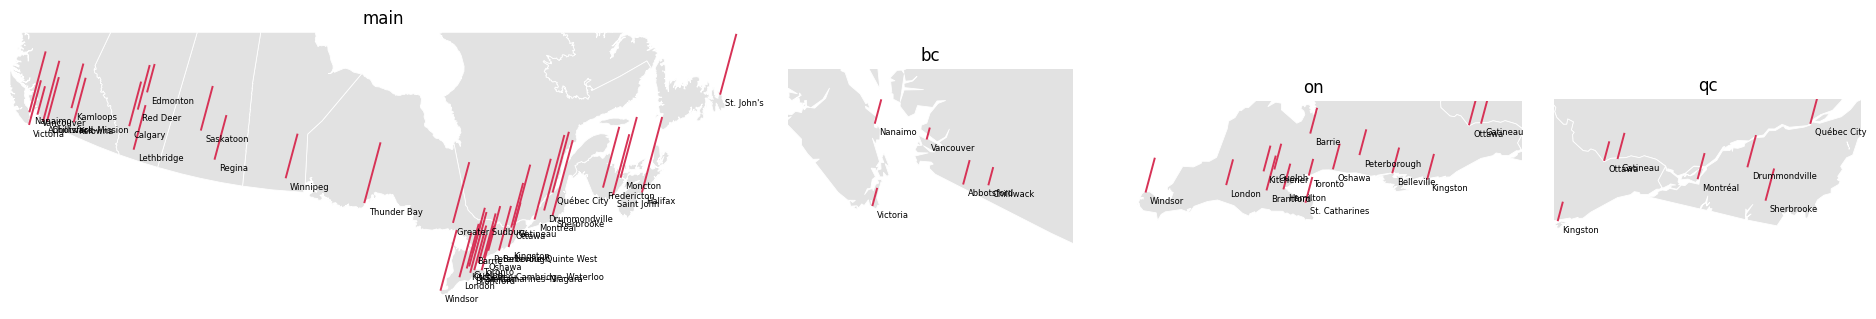

In [8]:
fig, axes = plt.subplots(1, len(frames), figsize=(19, 5), gridspec_kw={'width_ratios': [3.4, 1.3, 1.9, 1.4]})
for ax, fr, prv in zip(axes, frames, [main_prov] + [i['prov'] for i in INSETS]):
    prv.plot(ax=ax, color='#e2e2e2', edgecolor='white', linewidth=0.6)
    ext = fr['extent'] if fr['id'] == 'main' else fr['fit']
    pts = np.array([[p['x'], p['y']] for p in fr['points']]); idx = [p['i'] for p in fr['points']]
    scale_km = (ext[2] - ext[0]) / 700 * 55          # nominal 55 px at 700 px wide
    t = np.radians(ARROW_TILT_DEG)
    for (x, y), i in zip(pts, idx):
        L = len_frac[i] * scale_km * 1.3
        ax.plot([x, x + L * np.sin(t)], [y, y + L * np.cos(t)], color='#d73256', lw=1.4)
    for lab in fr['labels']:
        j = idx.index(lab['i']) if lab['i'] in idx else None
        if j is not None:
            ax.annotate(lab.get('text', net.loc[lab['i'], 'city']), pts[j], xytext=(3, -9), textcoords='offset points', fontsize=6)
    ax.set_xlim(ext[0], ext[2]); ax.set_ylim(ext[1], ext[3])
    ax.set_aspect('equal'); ax.axis('off'); ax.set_title(fr['id'])
plt.tight_layout()
plt.show()

### Export

One JSON file, `vis1_net_change_map.json`:

| key | contents |
|---|---|
| `meta` | measure description, baseline / latest quarter, city count, national and median net change, `arrow_tilt_deg` (chosen above) |
| `cities` | one row per city, longest bar first: `city`, `province`, `base_rent`, `latest_rent`, `pct_change` |
| `frames` | the national frame (`id: "main"`) followed by the insets. Every frame has `provinces` GeoJSON, `points` (`i` = index into `cities`, `x`, `y` in that frame's km coordinates) and `labels` (label priority order, optional `text`). `main` also has `extent` and `key_anchor`; insets have `fit` (the visible box), `extent` (the clipped geometry, larger), `region` (the visible box outlined on the national map), `rotation`, `order`, `row` and `zoom` |

In [9]:
cities = net[['city', 'province', 'base_rent', 'latest_rent', 'pct_change']].to_dict(orient='records')

vis1 = {
    'meta': {
        'measure': f'Net change in {BED_LABEL} asking rent, {BASELINE_QUARTER} to {LATEST_QUARTER}',
        'baseline_quarter': BASELINE_QUARTER,
        'latest_quarter': LATEST_QUARTER,
        'bedroom': BED_LABEL,
        'n_cities': int(len(cities)),
        'national_pct_change': float(nat_pct),
        'median_pct_change': round(float(net['pct_change'].median()), 1),
        'min_pct_change': float(net['pct_change'].min()),
        'max_pct_change': float(net['pct_change'].max()),
        'arrow_tilt_deg': ARROW_TILT_DEG,
        'class_breaks': CLASS_BREAKS,
        'excluded': sorted(DISPLAY_NAME.get(k, k.title()) for k in skipped),
    },
    'cities': cities,
    'frames': frames,
}

out = OUT_DIR / 'vis1_net_change_map.json'
with open(out, 'w') as f:
    json.dump(vis1, f, ensure_ascii=False, separators=(',', ':'))
print(f'saved: {out}  ({out.stat().st_size / 1024:.0f} KB, {len(cities)} cities, {len(frames)} frames)')

saved: ../../src/data/falling-rents/vis1_net_change_map.json  (91 KB, 40 cities, 4 frames)
